# Praktikum Kecerdasan Buatan — Text Classification

**Institut Teknologi Del** | 4233201 – Kecerdasan Buatan | Semester Ganjil TA 2026/2027

| | |
|---|---|
| **Tanggal Sesi** | 12 Oktober 2026 |
| **Minggu/Sesi** | 6/2 |
| **Topik** | Text Classification |
| **Tujuan Praktikum** | Mahasiswa mampu melakukan semua tahap dalam proses klasifikasi teks |
| **Durasi** | 2 x 50 menit |
| **Pengumpulan** | ecourse (akhir sesi) |

---

## Pendahuluan

Klasifikasi teks digunakan untuk mengelompokkan teks ke dalam kategori tertentu. Dalam praktikum ini akan dipelajari bagaimana melakukan klasifikasi teks mulai dari **preprocessing teks**, **ekstraksi fitur**, hingga **pelatihan model Naïve Bayes** untuk mendeteksi pesan **spam / bukan spam (ham)**.

### Alur Kerja (Pipeline)

1. Memuat dataset
2. Preprocessing teks (lowercase, hapus angka, hapus tanda baca, tokenisasi, stopword removal, lemmatization)
3. Encoding label (`ham` → 0, `spam` → 1) dan cek distribusi kelas
4. Pembagian data latih dan data uji (train-test split)
5. Ekstraksi fitur dengan TF-IDF (unigram + bigram)
6. Pelatihan model Multinomial Naïve Bayes
7. Evaluasi model (accuracy, classification report, confusion matrix)
8. Prediksi pada teks baru

## 1. Memuat Dataset

Dataset yang digunakan adalah `Text_classification.csv` yang berisi pesan SMS dengan dua kolom:

- **Category**: label pesan (`ham` = pesan normal, `spam` = pesan sampah/penipuan/iklan)
- **Message**: isi pesan teks

Dataset dimuat menggunakan **pandas**. Method `head()` menampilkan 5 baris pertama untuk melihat struktur data.

In [1]:
import os
import pandas as pd

# Path default untuk Google Colab; jika tidak ada, gunakan file di folder yang sama dengan notebook
path = '/content/Text_classification.csv'
if not os.path.exists(path):
    path = 'Text_classification.csv'

df = pd.read_csv(path)
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


Selanjutnya kita lihat ukuran dataset dan memastikan tidak ada nilai kosong (*missing values*), karena data kosong dapat menyebabkan error pada tahap preprocessing.

In [2]:
print("Ukuran dataset (baris, kolom):", df.shape)
print("\nJumlah missing value per kolom:\n", df.isnull().sum())

Ukuran dataset (baris, kolom): (5572, 2)

Jumlah missing value per kolom:
 Category    0
Message     0
dtype: int64


## 2. Preprocessing Teks dengan NLTK

**NLTK (Natural Language Toolkit)** adalah pustaka Python yang digunakan untuk membantu komputer dalam menganalisis, memproses, dan memahami teks tertulis. NLTK menyediakan alat untuk tokenisasi, stemming, lemmatization, stopword removal, dan analisis teks lainnya.

Teks mentah umumnya mengandung banyak *noise* (huruf besar/kecil tidak konsisten, angka, tanda baca, kata umum yang tidak informatif). Preprocessing bertujuan membersihkan teks agar model dapat fokus pada kata-kata yang bermakna.

### Tahapan preprocessing pada fungsi `clean_text`

| Tahap | Penjelasan | Contoh |
|---|---|---|
| **Lowercase** | Mengubah semua huruf menjadi huruf kecil agar `Free` dan `free` dianggap sama | `Free Entry` → `free entry` |
| **Hapus angka** | Menghapus digit menggunakan regex `\d+` | `win 2 tickets` → `win  tickets` |
| **Hapus tanda baca** | Menghapus karakter pada `string.punctuation` | `crazy..` → `crazy` |
| **Tokenisasi** | Memecah kalimat menjadi daftar kata (token) | `"ok lar"` → `['ok', 'lar']` |
| **Stopword removal** | Membuang kata umum bahasa Inggris (*the, is, in, to, ...*) yang kurang informatif | `['go', 'until', 'point']` → `['go', 'point']` |
| **Lemmatization** | Mengubah kata ke bentuk dasarnya (lemma) | `lives` → `life`, `tickets` → `ticket` |

> **Catatan:** Tanda baca dihapus sebelum tokenisasi, sehingga `don't` menjadi `dont`. Kata `dont` tidak ada dalam daftar stopword NLTK, sehingga tidak ikut terbuang (terlihat pada hasil baris ke-4).

Pertama, unduh resource NLTK yang diperlukan:
- `punkt` / `punkt_tab` → model tokenizer
- `stopwords` → daftar stopword
- `wordnet` → kamus untuk lemmatizer

In [3]:
# Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\glory\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\glory\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\glory\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\glory\AppData\Roaming\nltk_data...


True

Selanjutnya import library yang dibutuhkan, inisialisasi lemmatizer, dan definisikan fungsi `clean_text`.

*Optimasi kecil:* daftar stopword disimpan sekali dalam bentuk `set` (`stop_words`) agar pencarian lebih cepat dibandingkan memanggil `stopwords.words('english')` berulang-ulang untuk setiap kata. Hasilnya identik.

In [4]:
# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi lemmatizer dan daftar stopword
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()                                                    # Ubah menjadi lowercase
    text = re.sub(r'\d+', '', text)                                        # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))       # Hapus tanda baca
    words = word_tokenize(text)                                            # Tokenisasi
    words = [word for word in words if word not in stop_words]             # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words]                 # Lemmatization
    return ' '.join(words)

Fungsi diterapkan ke seluruh kolom `Message` dengan `apply()`. Hasilnya disimpan pada kolom baru `clean_text`, lalu dibandingkan dengan teks aslinya.

In [5]:
# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())


Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


## 3. Encoding Label dan Distribusi Kelas

Model machine learning membutuhkan label numerik, sehingga kolom `Category` diubah:

- `ham` → **0** (bukan spam)
- `spam` → **1** (spam)

Kemudian kita cek jumlah data pada masing-masing kelas dengan `value_counts()`.

In [6]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


**Analisis:** Dataset bersifat **tidak seimbang (imbalanced)**. Kelas ham (0) jauh lebih banyak dibandingkan kelas spam (1). Kondisi ini penting diperhatikan karena *accuracy* saja bisa menyesatkan: model yang selalu menebak "ham" pun sudah akan mendapat akurasi tinggi. Karena itu kita juga perlu melihat **precision, recall, dan F1-score** pada kelas spam.

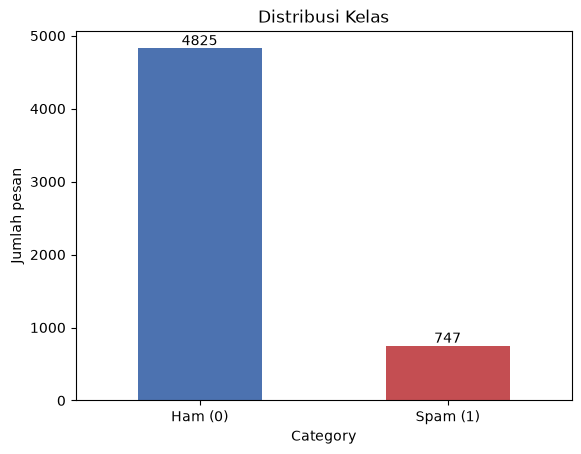

In [7]:
# Visualisasi distribusi kelas (opsional)
import matplotlib.pyplot as plt

ax = df['Category'].value_counts().sort_index().plot(kind='bar', color=['#4C72B0', '#C44E52'])
ax.set_xticklabels(['Ham (0)', 'Spam (1)'], rotation=0)
ax.set_ylabel('Jumlah pesan')
ax.set_title('Distribusi Kelas')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.show()

## 4. Pembagian Data (Train-Test Split)

Data dipisahkan menjadi **fitur** (`X` = teks bersih) dan **label** (`y` = kategori), lalu dibagi menjadi:

- **80% data latih** (*training*) untuk melatih model
- **20% data uji** (*testing*) untuk mengevaluasi model pada data yang belum pernah dilihat

Parameter penting:
- `test_size=0.2` → 20% untuk testing
- `random_state=42` → hasil pembagian dapat direproduksi
- `stratify=y` → proporsi ham dan spam pada data latih dan data uji tetap sama dengan dataset asli (penting untuk data imbalanced)

In [8]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Jumlah data latih :", len(X_train))
print("Jumlah data uji   :", len(X_test))

Jumlah data latih : 4457
Jumlah data uji   : 1115


## 5. Ekstraksi Fitur dengan TF-IDF

Komputer tidak dapat memproses teks secara langsung, sehingga teks harus diubah menjadi **vektor numerik**. Pada praktikum ini digunakan **TF-IDF (Term Frequency – Inverse Document Frequency)**.

$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t)$$

- **TF (Term Frequency)**: seberapa sering kata muncul dalam sebuah dokumen.
- **IDF (Inverse Document Frequency)**: seberapa jarang kata muncul di seluruh dokumen. Kata yang muncul di hampir semua dokumen mendapat bobot rendah, kata yang khas mendapat bobot tinggi.

Parameter yang digunakan:
- `ngram_range=(1,2)` → menggunakan **unigram** (satu kata) dan **bigram** (dua kata berurutan, misalnya `free entry`)
- `max_features=5000` → hanya mengambil 5000 fitur dengan frekuensi tertinggi untuk membatasi dimensi

**Penting:** `fit_transform` hanya dilakukan pada **data latih**, sedangkan data uji hanya `transform`. Hal ini mencegah *data leakage* (informasi data uji bocor ke proses pelatihan).

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000)  # Menggunakan unigram dan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)
print("TF-IDF Shape (Test) :", X_test_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)
TF-IDF Shape (Test) : (1115, 5000)


Output `(4457, 5000)` berarti terdapat 4457 dokumen latih, masing-masing direpresentasikan oleh 5000 fitur TF-IDF. Berikut contoh beberapa fitur (kata/bigram) yang dipelajari:

In [10]:
fitur = vectorizer.get_feature_names_out()
print("Jumlah fitur:", len(fitur))
print("Contoh 20 fitur pertama:", list(fitur[:20]))

Jumlah fitur: 5000
Contoh 20 fitur pertama: ['aah', 'abiola', 'able', 'abt', 'ac', 'acc', 'accept', 'access', 'accident', 'accidentally', 'account', 'account statement', 'ache', 'across', 'across sea', 'action', 'activate', 'activity', 'actually', 'ad']


## 6. Pelatihan Model Multinomial Naïve Bayes

**Naïve Bayes** adalah algoritma klasifikasi probabilistik berbasis **Teorema Bayes** dengan asumsi "naïf" bahwa setiap fitur saling independen:

$$P(C \mid x_1, \dots, x_n) \propto P(C) \prod_{i=1}^{n} P(x_i \mid C)$$

**MultinomialNB** cocok untuk data berupa frekuensi/bobot kata (seperti TF-IDF). Parameter `alpha=0.1` adalah **Laplace/Lidstone smoothing** agar kata yang tidak pernah muncul pada suatu kelas tidak menghasilkan probabilitas nol.

Model dilatih dengan `fit()` menggunakan data latih, kemudian `predict()` digunakan untuk memprediksi data uji.

In [11]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naive Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

## 7. Evaluasi Model

### 7.1 Accuracy dan Classification Report

Metrik yang digunakan:

- **Accuracy**: proporsi prediksi yang benar dari seluruh prediksi.
- **Precision**: dari semua yang diprediksi sebagai kelas tertentu, berapa yang benar. $\frac{TP}{TP+FP}$
- **Recall**: dari semua data yang sebenarnya kelas tertentu, berapa yang berhasil terdeteksi. $\frac{TP}{TP+FN}$
- **F1-score**: rata-rata harmonik precision dan recall. $2 \times \frac{P \times R}{P + R}$
- **Support**: jumlah data sebenarnya pada tiap kelas di data uji.

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



**Interpretasi hasil:**

- Akurasi sekitar **97,9%** menunjukkan model sangat baik secara keseluruhan.
- Kelas **ham (0)**: precision 0,98 dan recall 1,00 → hampir semua pesan ham dikenali dengan benar.
- Kelas **spam (1)**: precision 0,98 (jika model bilang spam, hampir pasti benar), namun recall 0,86 → sekitar 14% pesan spam **lolos** terdeteksi sebagai ham.
- *Macro avg* (rata-rata tanpa memperhatikan jumlah data) lebih rendah dari *weighted avg* karena performa pada kelas minoritas (spam) sedikit lebih rendah.

### 7.2 Confusion Matrix

**Confusion matrix** adalah tabel evaluasi yang menunjukkan bagaimana model klasifikasi bekerja dalam memprediksi kelas data.

- **True Positive (TP)**: Model benar memprediksi spam sebagai spam.
- **True Negative (TN)**: Model benar memprediksi ham sebagai ham.
- **False Positive (FP)**: Model salah memprediksi ham sebagai spam.
- **False Negative (FN)**: Model salah memprediksi spam sebagai ham.

| | Predicted Ham | Predicted Spam |
|---|---|---|
| **Actual Ham** | TN | FP |
| **Actual Spam** | FN | TP |

In [13]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])

# Label untuk TP, FP, FN, TN
labels = np.array([["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
                   ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])

Matriks divisualisasikan dalam bentuk **heatmap** dengan anotasi TN, FP, FN, dan TP agar mudah dibaca.

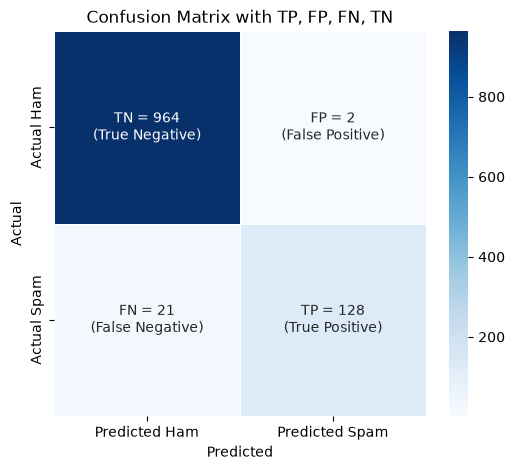

In [14]:
# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)

# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')
plt.show()

**Interpretasi:**

- **TN = 964** → 964 pesan ham diprediksi benar sebagai ham.
- **FP = 2** → hanya 2 pesan ham yang salah dianggap spam (sangat kecil, penting agar pesan normal tidak terblokir).
- **FN = 21** → 21 pesan spam lolos dan dianggap ham.
- **TP = 128** → 128 pesan spam berhasil terdeteksi.

Total data uji: 964 + 2 + 21 + 128 = **1115**. Model sangat konservatif: jarang salah memblokir pesan normal (FP rendah), tetapi masih ada spam yang lolos (FN lebih tinggi).

## 8. Prediksi pada Teks Baru

Model yang sudah dilatih dapat digunakan untuk memprediksi teks yang belum pernah dilihat. Langkahnya harus **konsisten dengan proses pelatihan**:

1. Preprocessing dengan `clean_text` (fungsi yang sama)
2. Transformasi dengan `vectorizer.transform` (**bukan** `fit_transform`, agar memakai kosakata dari data latih)
3. Prediksi dengan `model.predict`

In [15]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
             "Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


**Interpretasi:** Pesan pertama mengandung kata-kata khas spam (*congratulations, won, free, trip*) sehingga diprediksi **Spam**, sedangkan pesan kedua berupa percakapan sehari-hari sehingga diprediksi **Ham**.

Anda dapat mencoba pesan Anda sendiri pada sel berikut:

In [16]:
def prediksi_pesan(pesan):
    bersih = clean_text(pesan)
    vektor = vectorizer.transform([bersih])
    label = model.predict(vektor)[0]
    proba = model.predict_proba(vektor)[0]
    print(f"Pesan      : {pesan}")
    print(f"Prediksi   : {'Spam' if label == 1 else 'Ham'}")
    print(f"Probabilitas -> Ham: {proba[0]:.3f} | Spam: {proba[1]:.3f}\n")

prediksi_pesan("URGENT! Your mobile number has won a $1000 prize. Call now to claim!")
prediksi_pesan("Can you send me the assignment file before 5 pm?")

Pesan      : URGENT! Your mobile number has won a $1000 prize. Call now to claim!
Prediksi   : Spam
Probabilitas -> Ham: 0.000 | Spam: 1.000

Pesan      : Can you send me the assignment file before 5 pm?
Prediksi   : Ham
Probabilitas -> Ham: 0.933 | Spam: 0.067



## 9. Kesimpulan

1. Proses klasifikasi teks terdiri dari beberapa tahap: **preprocessing → ekstraksi fitur → pelatihan model → evaluasi → prediksi**.
2. Preprocessing (lowercase, penghapusan angka dan tanda baca, tokenisasi, stopword removal, lemmatization) membersihkan teks sehingga fitur yang dihasilkan lebih informatif.
3. **TF-IDF dengan unigram dan bigram** berhasil mengubah teks menjadi 5000 fitur numerik.
4. Model **Multinomial Naïve Bayes** (`alpha=0.1`) mencapai **akurasi ±97,9%** dengan F1-score kelas spam 0,92.
5. Karena data tidak seimbang, evaluasi tidak boleh hanya mengandalkan accuracy. Confusion matrix menunjukkan FP sangat rendah (2) namun FN masih 21, sehingga recall spam (0,86) masih dapat ditingkatkan.

### Ide pengembangan
- Mencoba teknik penanganan imbalanced data (oversampling/SMOTE, `class_weight`) untuk meningkatkan recall spam.
- Membandingkan dengan algoritma lain (Logistic Regression, SVM, Random Forest).
- Melakukan *hyperparameter tuning* (`alpha`, `ngram_range`, `max_features`) dengan `GridSearchCV`.